In [2]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\Sanna Sharma\Desktop\python\MachineLearning\venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [3]:
%pip install kaggle

  Obtaining dependency information for kaggle from https://files.pythonhosted.org/packages/45/ef/93bee59e708657b392f995fdaed2d3fd9b2959a2b20140560417ebefdaed/kaggle-2.2.5-py3-none-any.whl.metadata
  Obtaining dependency information for bleach from https://files.pythonhosted.org/packages/58/9d/40b6267367182187139a4000b82a3b287d84d745bccd808e75d916920e9d/bleach-6.4.0-py3-none-any.whl.metadata
  Obtaining dependency information for certifi>=2026.10.19 from https://files.pythonhosted.org/packages/32/d1/a3652fe2c19134d0d15922177821d863cbd7e842d53a21bbe7e8e3a1b5ac/certifi-2026.10.23-py3-none-any.whl.metadata
  Obtaining dependency information for jupytext from https://files.pythonhosted.org/packages/70/c3/c4eff5bdbe79b688dda8f06f2b66dbcf9a483cf660e5ced0b2dd5c21623d/jupytext-1.19.6-py3-none-any.whl.metadata
  Obtaining dependency information for kagglesdk<1.0,>=0.1.38 from https://files.pythonhosted.org/packages/a6/36/706d494627f24e2d46e1b481a2641111454754b168b5c823442734d9f0cf/kagglesdk-0.1.

ERROR: THESE PACKAGES DO NOT MATCH THE HASHES FROM THE REQUIREMENTS FILE. If you have updated the package versions, please update the hashes. Otherwise, examine the package contents carefully; someone may have tampered with them.
    unknown package:
        Expected sha256 381329a9f99628c9069361716891d34ad94af76e461dcb0335825aecc7692231
             Got        e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os

dataset_path = "dataset/cell_images"

print(os.path.exists(dataset_path))
print(os.listdir(dataset_path))

True
['cell_images', 'Parasitized', 'Uninfected']


In [9]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import random

In [11]:
dataset_path = "dataset/cell_images"

print(os.listdir(dataset_path))

['cell_images', 'Parasitized', 'Uninfected']


In [12]:
parasitized_path = os.path.join(dataset_path, "Parasitized")
uninfected_path = os.path.join(dataset_path, "Uninfected")

parasitized_images = [
    f for f in os.listdir(parasitized_path)
    if f.lower().endswith(".png")
]

uninfected_images = [
    f for f in os.listdir(uninfected_path)
    if f.lower().endswith(".png")
]

print("Parasitized images:", len(parasitized_images))
print("Uninfected images:", len(uninfected_images))

print("Total images:", len(parasitized_images) + len(uninfected_images))

Parasitized images: 13779
Uninfected images: 13779
Total images: 27558


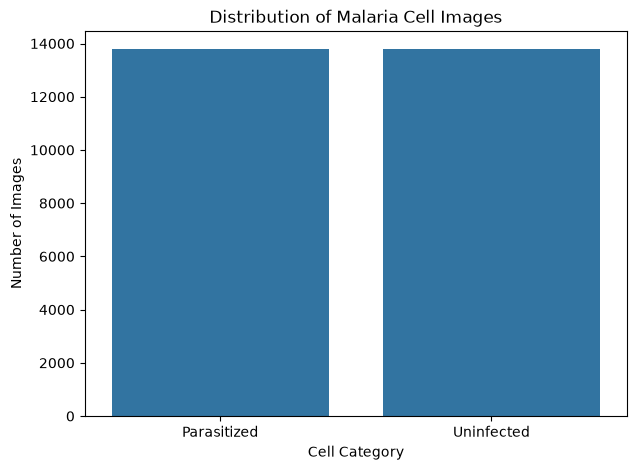

In [13]:
labels = ["Parasitized", "Uninfected"]

counts = [
    len(parasitized_images),
    len(uninfected_images)
]

plt.figure(figsize=(7, 5))

sns.barplot(x=labels, y=counts)

plt.title("Distribution of Malaria Cell Images")
plt.xlabel("Cell Category")
plt.ylabel("Number of Images")

plt.show()

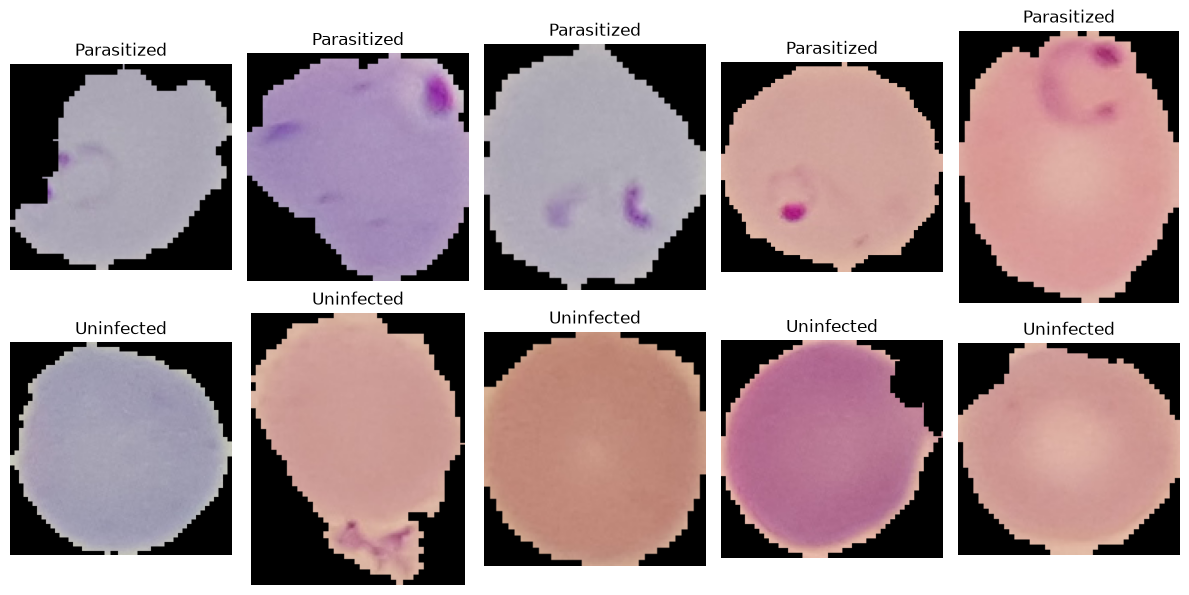

In [13]:
plt.figure(figsize=(12, 6))

for i in range(5):

    plt.subplot(2, 5, i + 1)

    img = Image.open(
        os.path.join(parasitized_path, random.choice(parasitized_images))
    )

    plt.imshow(img)
    plt.title("Parasitized")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)

    img = Image.open(
        os.path.join(uninfected_path, random.choice(uninfected_images))
    )

    plt.imshow(img)
    plt.title("Uninfected")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
sample_image = Image.open(
    os.path.join(parasitized_path, parasitized_images[0])
)

print("Image dimensions:", sample_image.size)
print("Image mode:", sample_image.mode)

Image dimensions: (142, 148)
Image mode: RGB


In [15]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [16]:
IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

In [17]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 55116 files belonging to 3 classes.


ValueError: When passing `label_mode="binary"`, there must be exactly 2 class_names. Received: class_names=['Parasitized', 'Uninfected', 'cell_images']